# h04 — Human MS: lymphocytes at lesion edges and cores, and the mouse RNA-localisation findings in human

**Part 1.** Demyelinated white matter (h02 zones) split into **edge** (a myelinated or partially myelinated
white-matter cell within 100 µm) and **core**; per section: lymphocytes and CD45-bright lymphocytes per mm², their
perivascular share (h03 definition), and myeloid phagocyte RNA (*CD68*, *GPNMB*, *SPP1*, *APOC1* per 1,000
transcripts) as the lesion-activity readout; myelinated white matter and meninges for reference.

**Part 2.** Two findings that replicated across mouse runs (notebook 23), tested in human MS spinal cord:
1. Lesion oligodendrocytes keep less *MBP* in the soma relative to their other myelin genes (mouse ×0.90).
2. Myeloid cells in lesions carry *less* myelin RNA relative to their surroundings than astrocytes (no engulfed-RNA
   trace; mouse ×0.86–0.88).
Plus the localisation check (most *MBP* outside cell outlines). Demyelinated white matter lies far from grey matter
in these sections (h03), so readout 1 is compared **within bands of distance to grey matter**.

One donor per section: descriptions per section, not tests across patients.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import yaml
from scipy.spatial import cKDTree

from beyondboundaries import plotting
from beyondboundaries.io import find_bundles

plotting.style()
SRC = "human/notebooks/h04_lesion_areas_and_mouse_tests.ipynb"
OUT = ROOT / "human" / "results" / "h04_lesion_areas_and_mouse_tests"
OUT.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load(open(ROOT / "human" / "config.yaml"))
SUB = ROOT / "human" / "data" / "subcellular"
MS = ["S07-256", "S13-019"]
LYMPH = "Lymphocyte (T/B/plasma)"
VESSEL = ["Endothelial", "Pericyte / VSMC", "Perivascular (mixed)"]
PHAGO = ["CD68", "GPNMB", "SPP1", "APOC1"]
SETS = {"mbp": ["MBP"], "myelin_ctrl": ["MAG", "MOG", "CLDN11", "MAL", "OPALIN", "ENPP6"],
        "myelin": ["MBP", "MAG", "MOG", "CNP", "CLDN11", "MAL", "OPALIN", "ENPP6", "MOBP"]}

In [2]:
a = ad.read_h5ad(CFG["annotation"]["h5ad"], backed="r")
genes = a.var_names.copy()
area = a.obs[["cell_area", "total_counts"]].copy()
ph = a[:, [g for g in PHAGO if g in genes]].to_memory().layers["counts"]
ph = np.asarray(ph.sum(1)).ravel()
a.file.close()
ct = pd.read_parquet(ROOT / "human" / "data" / "cell_types.parquet").join(
    pd.read_parquet(ROOT / "human" / "data" / "cell_zones.parquet"), how="inner").join(area)
ct["phago_per1k"] = pd.Series(ph, index=area.index).reindex(ct.index) / ct.total_counts.clip(lower=1) * 1000
bundles = find_bundles(CFG)
sec_of = {sid.split("_")[1]: sid for sid in bundles}
feats = []
for smp, sid in sec_of.items():
    f = pd.read_parquet(ROOT / CFG["features_dir"] / f"{sid}.parquet")
    if "cell_id" not in f.columns:
        f = f.reset_index()
    feats.append(f[["cell_id", "bnd_rim_mean", "bnd_ring_mean"]].assign(sample_id=smp))
d = ct.reset_index().merge(pd.concat(feats), on=["sample_id", "cell_id"], how="inner").set_index("index")
d = d[d.cell_type != "low quality"]
d["bnd_contrast"] = np.log(d.bnd_rim_mean.clip(lower=1) / d.bnd_ring_mean.clip(lower=1))
thr = d[d.cell_type == "Oligodendrocyte"].groupby("sample_id").bnd_contrast.quantile(0.95)
d["cd45_bright"] = (d.cell_type == LYMPH) & (d.bnd_contrast > d.sample_id.map(thr))
d["d_vessel"] = np.nan
for smp in d.sample_id.unique():
    g = d[d.sample_id == smp]
    v = g[g.cell_type.isin(VESSEL)]
    if len(v) < 10:
        continue
    dist, _ = cKDTree(v[["x_centroid", "y_centroid"]].to_numpy()).query(g[["x_centroid", "y_centroid"]].to_numpy(), k=2)
    d.loc[g.index, "d_vessel"] = np.where(g.index.isin(v.index), dist[:, 1], dist[:, 0])
# lesion edge vs core: a demyelinated cell with a myelinated/partial white-matter cell within 100 µm is "edge"
d["area"] = d.zone.replace({"demyelinated": "lesion core"})
for smp in d.sample_id.unique():
    g = d[d.sample_id == smp]
    L, M = g[g.zone == "demyelinated"], g[g.zone.isin(["myelinated", "partial"])]
    if len(L) and len(M):
        dist, _ = cKDTree(M[["x_centroid", "y_centroid"]].to_numpy()).query(L[["x_centroid", "y_centroid"]].to_numpy())
        d.loc[L.index[dist <= 100], "area"] = "lesion edge"
print(pd.crosstab(d.area, d.sample_id))

sample_id         Balo-1  Balo-2  S07-256  S13-019
area                                              
                      11       7       30        6
grey matter        24615   17748    16325     9004
lesion core           97     422    14228     6019
lesion edge           33    2846     9466     6533
meninges / roots     162       1    22419    12878
myelinated           121    8036    14843    33936
partial               18    5612    23955    20062
subpial rim          364    1084      647     1532


## Part 1. Lymphocytes at lesion edges and cores
Area per region from the number of 25 µm zone bins is not stored per cell, so densities are per 1,000 cells of
the region (cell density differs between regions; both are shown).

In [3]:
rows = []
for smp in d.sample_id.unique():
    g = d[d.sample_id == smp]
    for ar in ["myelinated", "partial", "lesion edge", "lesion core", "subpial rim", "meninges / roots"]:
        s = g[g.area == ar]
        if len(s) < 200:
            continue
        Ly = s[s.cell_type == LYMPH]
        my = s[s.cell_type.str.startswith("Myeloid")]
        rows.append(dict(sample=smp, region=ar, cells=len(s),
                         lymph_per_1k_cells=1000 * len(Ly) / len(s),
                         cd45_bright_per_1k_cells=1000 * Ly.cd45_bright.sum() / len(s),
                         lymph_perivascular=(Ly.d_vessel <= 20).mean() if len(Ly) >= 20 else np.nan,
                         myeloid_per_1k_cells=1000 * len(my) / len(s),
                         myeloid_phago_RNA_per1k=my.phago_per1k.median() if len(my) >= 20 else np.nan))
p1 = pd.DataFrame(rows)
p1.round(3).to_csv(OUT / "lesion_areas.csv", index=False)
p1.round(2)

,sample,region,cells,lymph_per_1k_cells,cd45_bright_per_1k_cells,lymph_perivascular,myeloid_per_1k_cells,myeloid_phago_RNA_per1k
0,S07-256,myelinated,14843,19.13,14.75,0.19,193.22,45.450001
1,S07-256,partial,23955,18.41,11.86,0.34,253.52,44.700001
2,S07-256,lesion edge,9466,20.81,13.10,0.56,258.61,35.130001
3,S07-256,lesion core,14228,31.98,16.10,0.25,276.36,22.650000
4,S07-256,subpial rim,647,89.64,55.64,0.05,102.01,4.910000
5,S07-256,meninges / roots,22419,44.47,23.69,0.22,85.11,3.400000
6,S13-019,myelinated,33936,37.63,23.37,0.30,247.47,33.090000
7,S13-019,partial,20062,64.65,33.45,0.44,255.51,29.760000
8,S13-019,lesion edge,6533,134.24,70.56,0.30,288.69,8.770000
9,S13-019,lesion core,6019,304.54,143.21,0.23,156.84,4.310000


PosixPath('/Users/christoffer/work/karolinska/development/BeyondBoundaries/human/results/h04_lesion_areas_and_mouse_tests/lesion_areas.png')

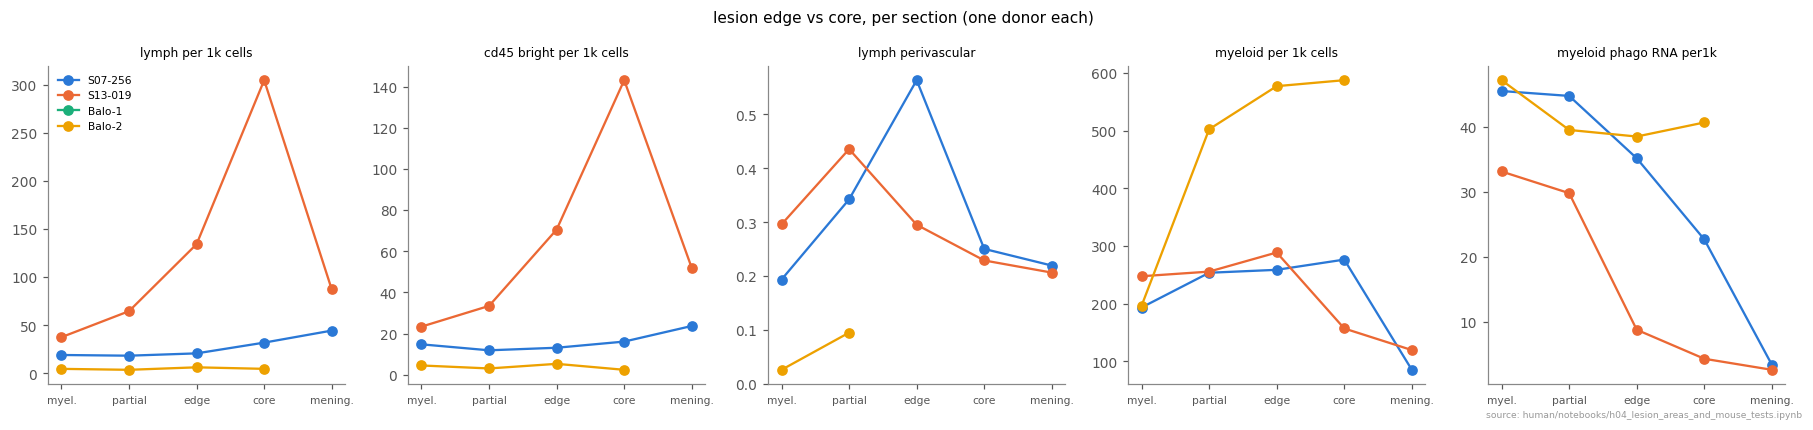

In [4]:
cols = ["lymph_per_1k_cells", "cd45_bright_per_1k_cells", "lymph_perivascular", "myeloid_per_1k_cells",
        "myeloid_phago_RNA_per1k"]
order = ["myelinated", "partial", "lesion edge", "lesion core", "meninges / roots"]
fig, axs = plt.subplots(1, len(cols), figsize=(3.3 * len(cols), 3.8))
for ax, c in zip(axs, cols):
    for k, smp in enumerate(["S07-256", "S13-019", "Balo-1", "Balo-2"]):
        t = p1[p1["sample"] == smp].set_index("region").reindex(order)
        ax.plot(range(len(order)), t[c], marker="o", color=plotting.CATEGORICAL[k], label=smp)
    ax.set_xticks(range(len(order)), ["myel.", "partial", "edge", "core", "mening."], fontsize=7)
    ax.set_title(c.replace("_", " "), fontsize=8)
axs[0].legend(fontsize=7)
fig.suptitle("lesion edge vs core, per section (one donor each)", fontsize=10)
fig.tight_layout()
plotting.save_fig(fig, "lesion_areas", OUT, SRC)

## Part 2. The mouse RNA-localisation findings in human
Per-cell counts from `human/scripts/02_transcript_compartments.py`: transcripts in the cell, in its nucleus, and
outside cells within 10 µm whose nearest cell it is ("halo"), with the free area of that halo.

In [5]:
gi = pd.Series(np.arange(len(genes)), index=genes)
sidx = {k: gi.reindex(v).dropna().astype(int).to_numpy() for k, v in SETS.items()}
parts = []
for smp, sid in sec_of.items():
    z = np.load(SUB / f"{sid}.npz", allow_pickle=True)
    names = z["obs_names"]
    n, G = len(names), len(genes)
    tot = sp.csr_matrix((z["total_data"], z["total_indices"], z["total_indptr"]), shape=(n, G))
    q = pd.DataFrame(index=pd.Index(names))
    for k, ix in sidx.items():
        q[f"{k}_cell"] = tot[:, ix].sum(1).A1
    q["halo_area"] = z["halo_area_um2"]
    p = pd.read_parquet(SUB / f"{sid}_points.parquet", columns=["gene", "in_cell", "near_cell", "dist_um"])
    h = p[~p.in_cell & (p.dist_um <= 10) & p.near_cell.notna()]
    q["halo_mbp"] = h[h.gene.astype(str) == "MBP"].groupby("near_cell").size().reindex(q.index).fillna(0)
    q["halo_myelin"] = h[h.gene.astype(str).isin(SETS["myelin"])].groupby("near_cell").size().reindex(q.index).fillna(0)
    parts.append(q)
q = pd.concat(parts)
q.index = q.index.astype(str)
d.index = d.index.astype(str)
c = d.join(q, how="inner")
print(f"{len(c):,} cells with transcript compartments")

253,060 cells with transcript compartments


In [6]:
rows = []
for smp in c.sample_id.unique():
    s = c[(c.sample_id == smp) & (c.zone == "myelinated")]
    inc, out = s.mbp_cell.sum(), s.halo_mbp.sum()
    rows.append(dict(sample=smp, mbp_in_cells=inc / (inc + out), mbp_transcripts=int(inc + out)))
san = pd.DataFrame(rows)
san.round(3).to_csv(OUT / "mbp_localisation_myelinated_wm.csv", index=False)
print("share of MBP transcripts inside cell outlines, myelinated white matter (outside = within 10 µm of a cell):")
san.round(2)

share of MBP transcripts inside cell outlines, myelinated white matter (outside = within 10 µm of a cell):


,sample,mbp_in_cells,mbp_transcripts
0,S07-256,0.18,574787
1,S13-019,0.27,1164976
2,Balo-1,0.35,3217
3,Balo-2,0.35,213777


**1. *MBP* ÷ control myelin genes in oligodendrocyte somata**, lesion (edge + core) vs myelinated white matter,
pooled counts per section, overall and within bands of distance to grey matter.

In [7]:
rows = []
ol = c[c.cell_type == "Oligodendrocyte"]
for smp in MS + ["Balo-1", "Balo-2"]:
    s = ol[ol.sample_id == smp]
    for band, m in [("all", np.ones(len(s), bool)), ("0–500 µm from GM", s.d_gm_um < 500),
                    ("500–1000 µm", s.d_gm_um.between(500, 1000)), ("> 1000 µm", s.d_gm_um > 1000)]:
        sb = s[m]
        les, hea = sb[sb.zone == "demyelinated"], sb[sb.zone == "myelinated"]
        if len(les) < 30 or len(hea) < 30:
            continue
        r_l = les.mbp_cell.sum() / les.myelin_ctrl_cell.sum()
        r_h = hea.mbp_cell.sum() / hea.myelin_ctrl_cell.sum()
        rows.append(dict(sample=smp, band=band, lesion_oligos=len(les), myelinated_oligos=len(hea),
                         mbp_over_ctrl_lesion=r_l, mbp_over_ctrl_myelinated=r_h, lesion_over_myelinated=r_l / r_h))
q1 = pd.DataFrame(rows)
q1.round(3).to_csv(OUT / "mbp_soma_lesion_vs_myelinated.csv", index=False)
q1.round(3)

,sample,band,lesion_oligos,myelinated_oligos,mbp_over_ctrl_lesion,mbp_over_ctrl_myelinated,lesion_over_myelinated
0,S07-256,all,3484,6560,1.792,1.961,0.914
1,S07-256,0–500 µm from GM,766,4298,1.685,1.937,0.870
2,S07-256,500–1000 µm,1463,2107,1.867,2.022,0.924
3,S07-256,> 1000 µm,1255,155,1.769,1.884,0.939
4,S13-019,all,576,14694,1.941,1.645,1.180
5,S13-019,0–500 µm from GM,131,7495,2.008,1.810,1.109
6,S13-019,500–1000 µm,72,4507,2.040,1.522,1.340
7,S13-019,> 1000 µm,373,2692,1.908,1.462,1.305
8,Balo-2,all,727,5396,1.490,1.676,0.889
9,Balo-2,0–500 µm from GM,144,1812,1.318,1.725,0.764


**2. Myelin RNA inside myeloid cells vs astrocytes in demyelinated white matter.** Uptake ratio = myelin
transcripts per µm² inside the outline ÷ myelin transcripts per µm² of free space in the cell's own halo (pooled per
section and cell group); myeloid ÷ astrocyte < 1 = no extra myelin RNA in the phagocytes.

In [8]:
def uptake(s):
    return (s.myelin_cell.sum() / s.cell_area.sum()) / (s.halo_myelin.sum() / s.halo_area.sum())


rows = []
for smp in c.sample_id.unique():
    for zn in ["demyelinated", "myelinated"]:
        s = c[(c.sample_id == smp) & (c.zone == zn)]
        my, ast = s[s.cell_type.str.startswith("Myeloid")], s[s.cell_type.str.startswith("Astrocyte")]
        if len(my) < 30 or len(ast) < 30:
            continue
        rows.append(dict(sample=smp, zone=zn, myeloid=len(my), astrocytes=len(ast), uptake_myeloid=uptake(my),
                         uptake_astrocyte=uptake(ast), myeloid_over_astrocyte=uptake(my) / uptake(ast)))
q2 = pd.DataFrame(rows)
q2.round(3).to_csv(OUT / "myeloid_myelin_uptake.csv", index=False)
q2.round(3)

,sample,zone,myeloid,astrocytes,uptake_myeloid,uptake_astrocyte,myeloid_over_astrocyte
0,S07-256,demyelinated,6380,6056,0.843,0.775,1.089
1,S07-256,myelinated,2868,3072,0.840,0.797,1.053
2,S13-019,demyelinated,2830,2170,1.398,1.038,1.347
3,S13-019,myelinated,8398,5898,0.942,0.876,1.075
4,Balo-2,demyelinated,1891,569,0.885,0.643,1.376
5,Balo-2,myelinated,1576,572,1.052,0.803,1.310


## Findings
One donor per section: descriptions per section, not tests across patients.

> **Part 1 — lesion areas differ between sections.** S13-019: lymphocytes rise from myelinated white matter (38 per
> 1,000 cells) to the lesion edge (134) and core (305), CD45-bright ones alike, while myeloid phagocyte RNA (*CD68*,
> *GPNMB*, *SPP1*, *APOC1*) is *low* in the lesions (4–9 per 1,000 transcripts vs 33 in myelinated white matter):
> lymphocyte-rich, phagocytically quiet lesions. S07-256 is milder (19 → 32 lymphocytes per 1,000 cells; 56 % of
> lesion-edge lymphocytes perivascular; phagocyte RNA 45 → 23). Balo-2 is the opposite: myeloid cells 3× denser in
> the lesion and phagocytic (~40), lymphocytes rare — a macrophage-driven active lesion.
>
> **Part 2 — the mouse RNA-localisation findings in human.**
> - *Most MBP lies outside cell bodies* (18–35 % inside, mouse 20 %): **replicates**.
> - *Lesion oligodendrocytes keep less MBP relative to their other myelin genes* (mouse ×0.90): S07-256 ×0.91 (×0.87–0.94
>   in every band of distance to grey matter), Balo-2 ×0.89, but S13-019 ×1.18 (opposite, every band): **mixed**.
> - *Myeloid cells hold less myelin RNA than astrocytes* (mouse ×0.86–0.88): in human myeloid cells hold *more*
>   everywhere (×1.05–1.31 in myelinated white matter, ×1.09–1.38 in lesions; S13-019 lesion ×1.35 vs ×1.08
>   myelinated): **does not replicate**. Engulfment in human lesions and species differences in cell shape would both
>   fit; one donor per section cannot separate them.